Implement dropout and batch normalization from scratch by manually modifying weight updates during training, ensuring proper variance stabilization and regularization without built-in layers.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

df = df[features + [target]].dropna()

X = df[features].astype(float).to_numpy()
y = df[target].astype(int).to_numpy()

print("Dataset shape:", df.shape)
print("Features:", features)

Dataset shape: (79, 6)
Features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']


In [2]:
np.random.seed(42)

indices = np.random.permutation(len(X))
split = int(0.8 * len(X))

train_idx = indices[:split]
test_idx = indices[split:]

X_train = X[train_idx]
X_test = X[test_idx]
y_train = y[train_idx].reshape(-1, 1)
y_test = y[test_idx].reshape(-1, 1)

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 63
Testing records: 16


In [3]:
np.random.seed(42)

input_size = X_train.shape[1]
hidden_size = 16

W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2 / input_size)
b1 = np.zeros((1, hidden_size))

gamma = np.ones((1, hidden_size))
beta = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, 1) * np.sqrt(1 / hidden_size)
b2 = np.zeros((1, 1))

running_mean = np.zeros((1, hidden_size))
running_var = np.ones((1, hidden_size))

learning_rate = 0.01
dropout_rate = 0.2
epsilon = 1e-8

In [4]:
epochs = 300
batch_size = 32
loss_history = []

for epoch in range(epochs):
    order = np.random.permutation(len(X_train))
    epoch_loss = 0

    for start in range(0, len(order), batch_size):
        batch_idx = order[start:start + batch_size]

        xb = X_train[batch_idx]
        yb = y_train[batch_idx]
        m = len(xb)

        # Forward pass
        z1 = xb @ W1 + b1

        batch_mean = z1.mean(axis=0, keepdims=True)
        batch_var = z1.var(axis=0, keepdims=True)
        inv_std = 1 / np.sqrt(batch_var + epsilon)

        xhat = (z1 - batch_mean) * inv_std
        z_bn = gamma * xhat + beta
        h = np.maximum(0, z_bn)

        running_mean = 0.9 * running_mean + 0.1 * batch_mean
        running_var = 0.9 * running_var + 0.1 * batch_var

        mask = (np.random.rand(*h.shape) > dropout_rate) / (1 - dropout_rate)
        h_drop = h * mask

        z2 = h_drop @ W2 + b2
        z2 = np.clip(z2, -30, 30)
        output = 1 / (1 + np.exp(-z2))

        loss = -np.mean(
            yb * np.log(output + epsilon)
            + (1 - yb) * np.log(1 - output + epsilon)
        )
        epoch_loss += loss * m

        # Backpropagation
        dz2 = (output - yb) / m
        dW2 = h_drop.T @ dz2
        db2 = np.sum(dz2, axis=0, keepdims=True)

        dh = (dz2 @ W2.T) * mask
        dz_bn = dh * (z_bn > 0)

        dgamma = np.sum(dz_bn * xhat, axis=0, keepdims=True)
        dbeta = np.sum(dz_bn, axis=0, keepdims=True)

        dxhat = dz_bn * gamma
        dz1 = (inv_std / m) * (
            m * dxhat
            - np.sum(dxhat, axis=0, keepdims=True)
            - xhat * np.sum(dxhat * xhat, axis=0, keepdims=True)
        )

        dW1 = xb.T @ dz1
        db1 = np.sum(dz1, axis=0, keepdims=True)

        # Update parameters
        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2
        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1
        gamma -= learning_rate * dgamma
        beta -= learning_rate * dbeta

    loss_history.append(epoch_loss / len(X_train))

print("Training completed.")
print("Final training loss:", round(loss_history[-1], 4))

Training completed.
Final training loss: 0.4319


In [5]:
z1_test = X_test @ W1 + b1

xhat_test = (
    (z1_test - running_mean)
    / np.sqrt(running_var + epsilon)
)

z_bn_test = gamma * xhat_test + beta
h_test = np.maximum(0, z_bn_test)

z2_test = np.clip(h_test @ W2 + b2, -30, 30)
probabilities = 1 / (1 + np.exp(-z2_test))

predictions = (probabilities >= 0.5).astype(int)

accuracy = np.mean(predictions == y_test) * 100

print("Test Accuracy:", round(accuracy, 2), "%")

Test Accuracy: 93.75 %


In [6]:
tp = np.sum((y_test == 1) & (predictions == 1))
tn = np.sum((y_test == 0) & (predictions == 0))
fp = np.sum((y_test == 0) & (predictions == 1))
fn = np.sum((y_test == 1) & (predictions == 0))

precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)

print("Accuracy:", round(accuracy, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1-Score:", round(f1 * 100, 2), "%")

Accuracy: 93.75 %
Precision: 92.86 %
Recall: 100.0 %
F1-Score: 96.3 %


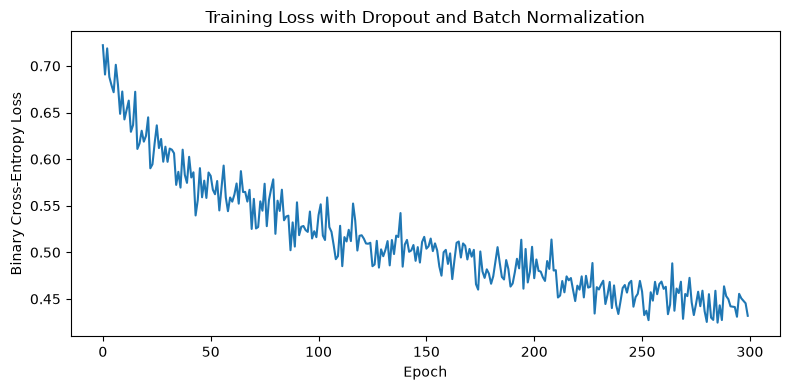

In [7]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training Loss with Dropout and Batch Normalization")
plt.tight_layout()
plt.show()